# GSE60450 with edgerpy

This book runs the edgeR v4 quasi-likelihood pipeline in Python with **edgerpy**, from Salmon's output files to
differential expression and differential transcript usage.

**Data.** GEO accession GSE60450: RNA-seq of basal and luminal cells from the mammary glands of virgin, pregnant
and lactating mice, two samples per group, 12 in total. Each sample was quantified by Salmon against the Gencode
mouse transcriptome with 100 Gibbs samples, giving 276,623 transcripts.

The sections follow the pipeline: reading the Salmon output (`catchSalmon`); filtering, normalisation and
exploration; negative binomial dispersions; the quasi-likelihood fit; differential expression; and differential
transcript usage.


## The data

The reads are from GEO accession GSE60450, SRA runs SRR1552444 to SRR1552455 (single-end). Each run was
quantified with Salmon 1.10.3 against an index of the Gencode mouse transcriptome (276,623 transcripts),
with 100 Gibbs samples:

```sh
salmon quant -i <index> -l A -r SRR1552444.fastq --numGibbsSamples 100 -o SRR1552444
```

The 12 output folders go in one folder; set `SALMON` in the next cell to it.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import edgerpy as ep

SALMON = Path("Salmon")     # the folder holding the 12 Salmon output folders

## Reading the Salmon output

The experiment has 12 RNA-seq samples, one Salmon run each. `catchSalmon` reads each run's
`quant.sf` (transcript counts), `meta_info.json` and the 100 Gibbs samples Salmon drew of each transcript's count.

Reads that map to several transcripts of a gene can't be assigned with certainty, so a transcript's count is more
variable than a Poisson count would be. From the Gibbs samples, `catchSalmon` estimates this extra variability,
the **overdispersion**, for every transcript. Dividing the counts by it gives counts that behave like ordinary
gene counts in the rest of the pipeline. This takes about a minute.

In [2]:
y0 = ep.catchSalmon(SALMON)

Reading SRR1552444, 276623 transcripts, 100 gibbs samples


Reading SRR1552445, 276623 transcripts, 100 gibbs samples


Reading SRR1552446, 276623 transcripts, 100 gibbs samples


Reading SRR1552447, 276623 transcripts, 100 gibbs samples


Reading SRR1552448, 276623 transcripts, 100 gibbs samples


Reading SRR1552449, 276623 transcripts, 100 gibbs samples


... (2 outputs left out)

Reading SRR1552452, 276623 transcripts, 100 gibbs samples


Reading SRR1552453, 276623 transcripts, 100 gibbs samples


Reading SRR1552454, 276623 transcripts, 100 gibbs samples


Reading SRR1552455, 276623 transcripts, 100 gibbs samples


The result is a DGEList: the divided counts, one row per transcript, and the annotation unpacked
from the Gencode transcript names (gene ID `EnsG`, gene symbol `GeneName`, biotype `Type`), together with each
transcript's length and overdispersion.

In [3]:
y0["counts"].shape

(276623, 12)

In [4]:
y0["genes"].head()

,Length,AveEffLen,Max2MinEffLen,Overdispersion,EnsG,HavG,HavT,TxName,GeneName,Type
ENSMUST00000193812,1070.0,820.000,1.0,1.030187,ENSMUSG00000102693,OTTMUSG00000049935,OTTMUST00000127109.1,4933401J01Rik-201,4933401J01Rik,TEC
ENSMUST00000082908,110.0,3.749,1.0,1.030187,ENSMUSG00000064842,-,-,Gm26206-201,Gm26206,snRNA
ENSMUST00000162897,4153.0,3903.000,1.0,2.263370,ENSMUSG00000051951,OTTMUSG00000026353,OTTMUST00000086625.1,Xkr4-203,Xkr4,protein_coding_CDS_not_defined
ENSMUST00000159265,2989.0,2739.000,1.0,1.912286,ENSMUSG00000051951,OTTMUSG00000026353,OTTMUST00000086624.1,Xkr4-202,Xkr4,protein_coding_CDS_not_defined
ENSMUST00000070533,3634.0,3384.000,1.0,1.272144,ENSMUSG00000051951,OTTMUSG00000026353,OTTMUST00000065166.1,Xkr4-201,Xkr4,protein_coding


In [5]:
y0["genes"]["Overdispersion"].describe()

count    276623.000000
mean          2.278901
std           4.613406
min           1.000000
25%           1.030187
50%           1.069635
75%           1.573411
max         186.143963
Name: Overdispersion, dtype: float64

### Sample groups

The samples are basal (B) and luminal (L) cells from the mammary glands of virgin, pregnant (day 18.5) and lactating
(day 2) mice, two of each. The Salmon folders are in the order SRR1552444 to SRR1552455: the six luminal samples
first, then the six basal ones.

In [6]:
celltype = np.repeat(["L", "B"], 6)
status = np.tile(np.repeat(["virgin", "pregnant", "lactating"], 2), 2)
group = pd.Categorical([f"{c}.{s}" for c, s in zip(celltype, status)])
s = y0["samples"].copy()
s["group"] = group
y0["samples"] = s
y0["samples"]

,group,lib.size,norm.factors
SRR1552444,L.virgin,1.412689e+07,1.0
SRR1552445,L.virgin,1.506301e+07,1.0
SRR1552446,L.pregnant,1.530225e+07,1.0
SRR1552447,L.pregnant,1.517559e+07,1.0
SRR1552448,L.lactating,1.713410e+07,1.0
SRR1552449,L.lactating,1.702043e+07,1.0
SRR1552450,B.virgin,1.537699e+07,1.0
SRR1552451,B.virgin,1.453351e+07,1.0
SRR1552452,B.pregnant,1.587023e+07,1.0
SRR1552453,B.pregnant,1.489218e+07,1.0


## Filtering, normalisation and exploration

In [7]:
group = y0["samples"]["group"].array

### Design matrix

One coefficient per group (`~0 + group`), so each contrast below is a difference between two group means.

In [8]:
design = ep.modelMatrix("~0 + group", pd.DataFrame({"group": group}))
design

,B.lactating,B.pregnant,B.virgin,L.lactating,L.pregnant,L.virgin
1,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0
5,0.0,0.0,0.0,1.0,0.0,0.0
6,0.0,0.0,0.0,1.0,0.0,0.0
7,0.0,0.0,1.0,0.0,0.0,0.0
8,0.0,0.0,1.0,0.0,0.0,0.0
9,0.0,1.0,0.0,0.0,0.0,0.0
10,0.0,1.0,0.0,0.0,0.0,0.0


### Filtering

Most of the 276,623 transcripts have too few reads to test. `filterByExpr` keeps those with enough counts in
enough samples, given the design. The library sizes are then recomputed from the kept transcripts.

In [9]:
keep = ep.filterByExpr(y0, design)
y = y0.subset(keep, None, keep_lib_sizes=False)
pd.Series(keep).value_counts()

False    237965
True      38658
Name: count, dtype: int64

### Normalisation

TMM normalisation factors correct for differences in RNA composition between samples.

In [10]:
y = ep.normLibSizes(y)
y["samples"]

,group,lib.size,norm.factors
SRR1552444,L.virgin,1.402308e+07,1.354358
SRR1552445,L.virgin,1.495068e+07,1.327603
SRR1552446,L.pregnant,1.522401e+07,1.026911
SRR1552447,L.pregnant,1.510103e+07,0.943648
SRR1552448,L.lactating,1.707851e+07,0.511420
SRR1552449,L.lactating,1.696072e+07,0.529061
SRR1552450,B.virgin,1.527355e+07,1.241166
SRR1552451,B.virgin,1.443638e+07,1.190879
SRR1552452,B.pregnant,1.577021e+07,1.154849
SRR1552453,B.pregnant,1.480069e+07,1.086439


### Log counts per million

`cpm` gives each sample's normalised log2 counts per million, and `aveLogCPM` each transcript's average
abundance.

In [11]:
logcpm = ep.cpm(y, log=True)
logcpm.iloc[:6, :6].round(3)

,SRR1552444,SRR1552445,SRR1552446,SRR1552447,SRR1552448,SRR1552449
ENSMUST00000162897,-2.947,-2.947,-2.947,-2.947,-2.947,-2.947
ENSMUST00000159265,-2.947,-2.947,-2.947,-2.947,-2.400,-2.947
ENSMUST00000070533,-2.947,-2.947,-2.947,-2.947,-2.947,-2.947
ENSMUST00000161581,-2.947,-2.947,-2.947,-2.947,-2.947,-2.947
ENSMUST00000027035,-1.396,-0.802,-2.947,-1.509,-1.914,-2.947
ENSMUST00000195555,-2.947,-2.947,-1.251,-2.947,-2.947,-2.250


In [12]:
pd.Series(ep.aveLogCPM(y)).describe()

count    38658.000000
mean         1.457711
std          2.404776
min         -2.067656
25%         -0.429903
50%          0.744311
75%          2.801353
max         15.702061
dtype: float64

### Multidimensional scaling

Distances between samples from their leading log-fold-changes. The first dimension separates basal from luminal
cells; the second separates the pregnancy and lactation stages.

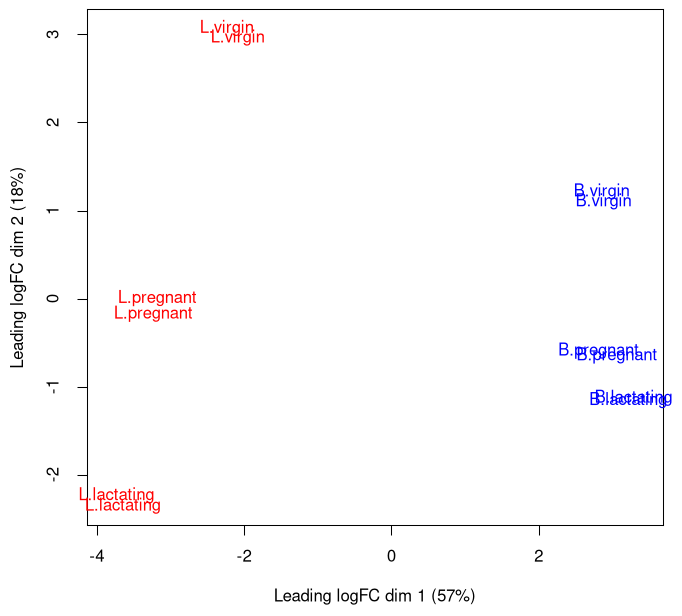

In [13]:
mds = ep.plotMDS(y, labels=list(group), col=["red"] * 6 + ["blue"] * 6)

In [14]:
np.round(mds["var.explained"][:4], 4)

array([0.5687, 0.1769, 0.0636, 0.042 ])

## Negative binomial dispersions

The quasi-likelihood fit in the next section does not need dispersion estimates: in edgeR v4 the
negative binomial dispersion is estimated within `glmQLFit`. `estimateDisp` is still a useful look at the data's
biological variability, which this section shows.

In [15]:
yd = ep.estimateDisp(y, design)
yd["common.dispersion"], yd["prior.df"]

(0.01855989756536885, array([8.65956116]))

The biological coefficient of variation (BCV) is the square root of the dispersion. Its common
value across all transcripts:

In [16]:
np.sqrt(yd["common.dispersion"])

np.float64(0.1362347149788513)

The BCV plot shows each transcript's BCV against its abundance, with the common value (red) and the
abundance trend (blue). Transcripts with low counts are more variable.

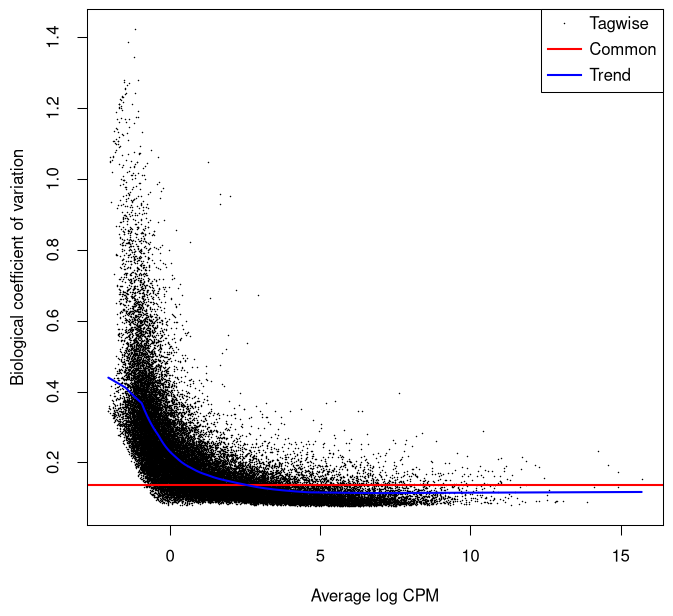

In [17]:
ep.plotBCV(yd)

## Quasi-likelihood fit

`glmQLFit` fits a negative binomial GLM to each transcript and estimates a quasi-likelihood (QL)
dispersion for it. The QL dispersions are squeezed towards a trend in abundance with empirical Bayes; `robust=True`
protects against transcripts with unusually large dispersions.

In [18]:
fit = ep.glmQLFit(y, design, robust=True)
pd.Series(fit["df.prior"]).describe()

count    38658.000000
mean        10.251220
std          0.151724
min          0.427334
25%         10.255426
50%         10.255426
75%         10.255426
max         10.255426
dtype: float64

The plot shows the raw QL dispersions (black), the abundance trend (blue) and the squeezed
values (red) on the quarter-root scale.

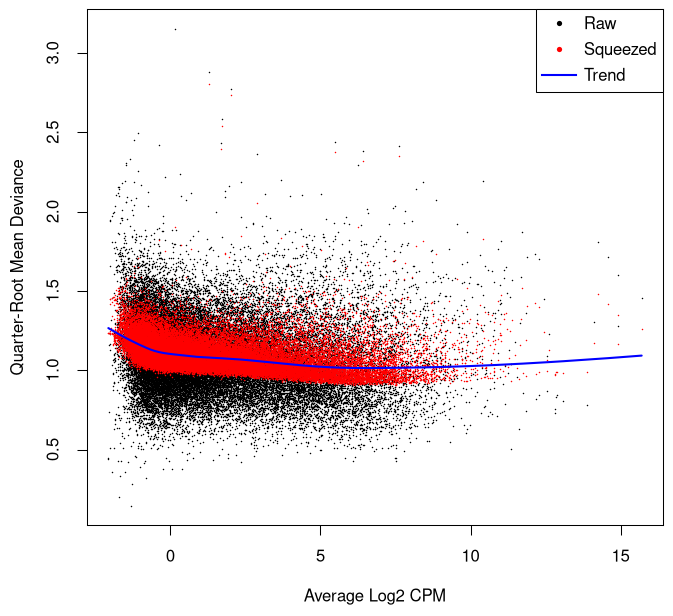

In [19]:
ep.plotQLDisp(fit);

## Differential expression

In [20]:
fit["design"].columns.tolist()

['B.lactating',
 'B.pregnant',
 'B.virgin',
 'L.lactating',
 'L.pregnant',
 'L.virgin']

### Two tests

The columns of the design are the group means, in the order above. The first test compares basal cells of pregnant
and lactating mice (one contrast). The second is an F-test on two luminal contrasts at once (pregnant vs lactating,
virgin vs lactating): it finds transcripts that change anywhere across the three luminal stages.

In [21]:
B_PvsL = [-1, 1, 0, 0, 0, 0]
res = ep.glmQLFTest(fit, contrast=B_PvsL)
L_anova = np.column_stack([[0, 0, 0, -1, 1, 0], [0, 0, 0, -1, 0, 1]])
resA = ep.glmQLFTest(fit, contrast=L_anova)
res["comparison"], resA["comparison"]

('-1*B.lactating 1*B.pregnant', 'LR test on 2 degrees of freedom')

### Top transcripts

`topTags` sorts the transcripts by p-value and adds the Benjamini-Hochberg FDR.

In [22]:
top = ep.topTags(res, n=10)
top["table"][["GeneName", "Type", "logFC", "logCPM", "F", "PValue", "FDR"]]

,GeneName,Type,logFC,logCPM,F,PValue,FDR
ENSMUST00000072539,Csn1s2b,protein_coding,-6.181915,10.340621,534.215283,2.767714e-13,1.069943e-08
ENSMUST00000105971,Tnni2,protein_coding,-5.638132,3.303729,334.171236,2.411801e-12,4.631263e-08
ENSMUST00000051401,Cldn4,protein_coding,5.248025,10.360691,321.991616,3.848730e-12,4.631263e-08
ENSMUST00000033386,Mrgprf,protein_coding,-5.152265,2.654883,521.866825,5.096596e-12,4.631263e-08
ENSMUST00000027217,Ecrg4,protein_coding,2.746273,7.250335,246.712721,5.990044e-12,4.631263e-08
ENSMUST00000060419,Gjb4,protein_coding,5.426715,4.910936,253.422946,1.179513e-11,7.599601e-08
ENSMUST00000023807,Igfbp6,protein_coding,-2.946995,4.135948,273.396667,1.425350e-11,7.871598e-08
ENSMUST00000205120,Creb5,protein_coding,-2.598429,5.226838,254.973084,2.332988e-11,1.021598e-07
ENSMUST00000034618,Nherf4,protein_coding,-3.329458,2.189392,237.524609,2.378390e-11,1.021598e-07
ENSMUST00000239554,Muc4,protein_coding,7.827385,6.349917,211.255953,4.628704e-11,1.789364e-07


In [23]:
topA = ep.topTags(resA, n=10)
topA["table"].drop(columns=["Length", "AveEffLen", "Max2MinEffLen", "Overdispersion", "EnsG", "HavG", "HavT",
                            "TxName"])

,GeneName,Type,logFC.1,logFC.2,logCPM,F,PValue,FDR
ENSMUST00000101534,Ptn,protein_coding,-1.598161,7.241769,9.081179,1767.044078,9.713625e-20,3.755093e-15
ENSMUST00000072539,Csn1s2b,protein_coding,-8.647331,-11.486991,10.340621,1669.526470,1.396017e-18,2.698362e-14
ENSMUST00000228895,Glycam1,protein_coding,-3.264861,-10.873009,7.867767,902.801428,3.454451e-18,4.451405e-14
ENSMUST00000196585,Csn1s2a,protein_coding,-1.897307,-7.968493,5.401014,774.711242,5.965369e-18,5.765231e-14
ENSMUST00000141868,Wap,protein_coding_CDS_not_defined,-4.079309,-11.355584,6.125267,835.892164,9.081124e-18,6.468084e-14
ENSMUST00000023134,Glycam1,protein_coding,-2.814834,-11.118662,14.923928,995.095004,1.003893e-17,6.468084e-14
ENSMUST00000085818,Kcnk6,protein_coding,-2.464073,-7.008541,6.424876,912.120765,2.030567e-17,9.865100e-14
ENSMUST00000040404,Ly6d,protein_coding,3.602686,9.479272,5.206592,818.494145,2.041513e-17,9.865100e-14
ENSMUST00000113279,Csn1s2b,protein_coding,-9.630766,-12.654383,3.027422,645.765233,2.567809e-17,1.007982e-13
ENSMUST00000003622,Slc25a1,protein_coding,-4.143123,-4.942965,7.206019,883.889466,2.607435e-17,1.007982e-13


### How many transcripts change

`decideTests` calls each transcript up, down or not significant at FDR 0.05.

In [24]:
ep.decideTests(res).summary()

,-1*B.lactating 1*B.pregnant
Down,2742
NotSig,32896
Up,3020


In [25]:
ep.decideTests(resA).summary()

,LR test on 2 degrees of freedom
NotSig,22223
Sig,16435


### Mean-difference plot

Log-fold-change against average abundance for basal pregnant vs lactating, significant transcripts coloured.

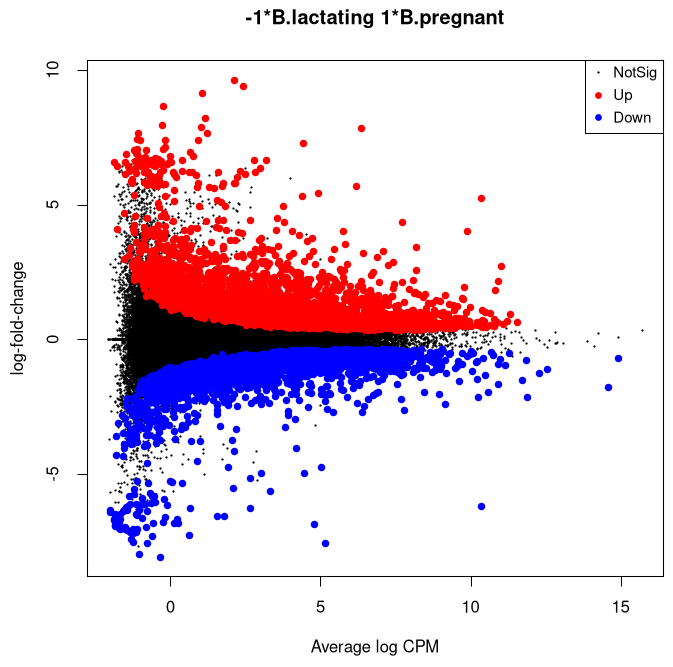

In [26]:
ep.plotMD(res)

## Differential transcript usage

A gene can keep its total expression but switch which of its transcripts it makes. `diffSplice`
tests for this: for each transcript it compares the transcript's log-fold-change with that of the other transcripts
of the same gene. Here the comparison is again basal pregnant vs lactating, and genes are grouped by their Ensembl
gene ID (`EnsG`).

In [27]:
sp = ep.diffSplice(fit, contrast=B_PvsL, geneid="EnsG")

Total number of exons:  38658
Total number of genes:  17566
Number of genes with 1 exon:  8636
Mean number of exons in a gene:  2
Max number of exons in a gene:  23


### Gene-level and transcript-level results

`topSplice` ranks genes by a gene-level F-test or Simes-adjusted p-value, or ranks individual transcripts with a
t-test.

In [28]:
ep.topSplice(sp, test="simes", number=10)[["EnsG", "GeneName", "NExons", "P.Value", "FDR"]]

,EnsG,GeneName,NExons,P.Value,FDR
ENSMUSG00000031565,ENSMUSG00000031565,Fgfr1,11.0,2.454451e-13,1.438926e-09
ENSMUSG00000033685,ENSMUSG00000033685,Ucp2,9.0,3.222680e-13,1.438926e-09
ENSMUSG00000057440,ENSMUSG00000057440,Mpp7,5.0,2.367894e-12,7.048430e-09
ENSMUSG00000027381,ENSMUSG00000027381,Bcl2l11,5.0,3.966774e-11,8.855824e-08
ENSMUSG00000032332,ENSMUSG00000032332,Col12a1,6.0,1.578872e-10,2.819866e-07
ENSMUSG00000033228,ENSMUSG00000033228,Scaf11,4.0,3.413727e-10,5.080763e-07
ENSMUSG00000133829,ENSMUSG00000133829,ENSMUSG00000133829,4.0,1.007186e-09,1.284881e-06
ENSMUSG00000026280,ENSMUSG00000026280,Atg4b,7.0,2.183568e-09,2.437408e-06
ENSMUSG00000001794,ENSMUSG00000001794,Capns1,6.0,2.566998e-09,2.547032e-06
ENSMUSG00000019907,ENSMUSG00000019907,Ppp1r12a,7.0,5.875309e-09,5.246651e-06


In [29]:
ep.topSplice(sp, test="F", number=10)[["EnsG", "GeneName", "NExons", "F", "P.Value", "FDR"]]

,EnsG,GeneName,NExons,F,P.Value,FDR
ENSMUSG00000031565,ENSMUSG00000031565,Fgfr1,11.0,16.073201,5.174726e-16,4.621031e-12
ENSMUSG00000026280,ENSMUSG00000026280,Atg4b,7.0,18.352152,5.986463e-12,2.337492e-08
ENSMUSG00000001794,ENSMUSG00000001794,Capns1,6.0,21.746557,7.852718e-12,2.337492e-08
ENSMUSG00000057440,ENSMUSG00000057440,Mpp7,5.0,25.025652,2.849366e-11,6.361210e-08
ENSMUSG00000033685,ENSMUSG00000033685,Ucp2,9.0,12.617266,4.303890e-11,7.686748e-08
ENSMUSG00000027381,ENSMUSG00000027381,Bcl2l11,5.0,23.553715,8.364384e-11,1.244899e-07
ENSMUSG00000032332,ENSMUSG00000032332,Col12a1,6.0,18.719292,2.330699e-10,2.973306e-07
ENSMUSG00000062991,ENSMUSG00000062991,Nrg1,10.0,9.536788,1.678632e-09,1.857144e-06
ENSMUSG00000033228,ENSMUSG00000033228,Scaf11,4.0,25.247061,1.895384e-09,1.857144e-06
ENSMUSG00000031167,ENSMUSG00000031167,Rbm3,8.0,11.485684,2.079668e-09,1.857144e-06


In [30]:
ep.topSplice(sp, test="t", number=10)[["EnsG", "GeneName", "TxName", "logFC", "t", "P.Value", "FDR"]]

,EnsG,GeneName,TxName,logFC,t,P.Value,FDR
ENSMUST00000210504,ENSMUSG00000031565,Fgfr1,Fgfr1-214,1.075914,9.133033,2.231319e-14,5.375071e-10
ENSMUST00000126381,ENSMUSG00000033685,Ucp2,Ucp2-201,1.587331,9.440303,3.580755e-14,5.375071e-10
ENSMUST00000233992,ENSMUSG00000057440,Mpp7,Mpp7-202,3.138541,9.782039,4.735787e-13,4.739260e-09
ENSMUST00000110341,ENSMUSG00000027381,Bcl2l11,Bcl2l11-204,-1.222829,-8.976698,7.933548e-12,5.954525e-08
ENSMUST00000071750,ENSMUSG00000032332,Col12a1,Col12a1-201,-1.611539,-8.567863,2.631454e-11,1.580030e-07
ENSMUST00000227133,ENSMUSG00000033228,Scaf11,Scaf11-203,1.399000,8.627470,8.534316e-11,4.270287e-07
ENSMUST00000321006,ENSMUSG00000133829,ENSMUSG00000133829,ENSMUST00000321006,6.203166,8.338490,2.517965e-10,1.079919e-06
ENSMUST00000126116,ENSMUSG00000001794,Capns1,Capns1-203,-1.447584,-7.615726,4.278329e-10,1.605550e-06
ENSMUST00000027502,ENSMUSG00000026280,Atg4b,Atg4b-201,-0.994721,-7.380645,5.743702e-10,1.873002e-06
ENSMUST00000135762,ENSMUSG00000026280,Atg4b,Atg4b-202,1.239537,7.359587,6.238766e-10,1.873002e-06


### The top gene

Each transcript's log-fold-change relative to the rest of its gene; significant transcripts are in red.

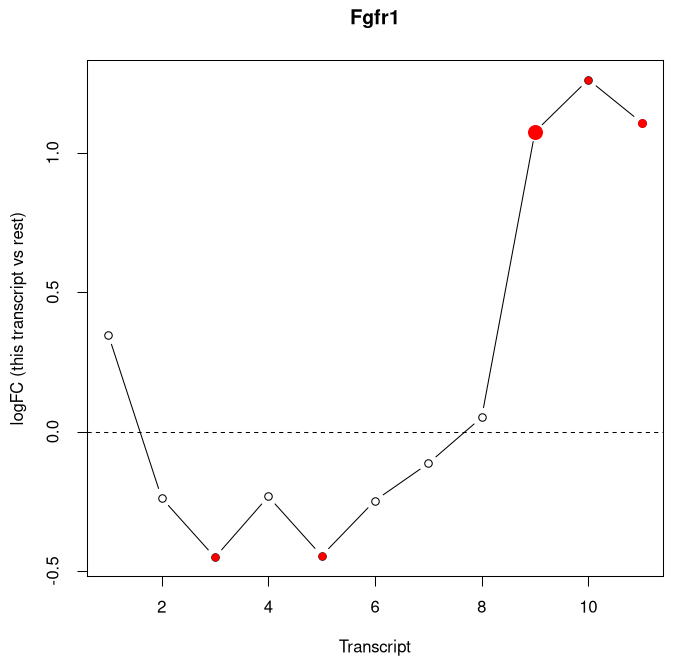

In [31]:
ep.plotSplice(sp, genecolname="GeneName", xlab="Transcript")